In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [105]:
df = pd.read_csv('data/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [106]:
df = pd.read_csv('data/Mall_Customers.csv')
df.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [3]:
df.shape

(200, 5)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [5]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [7]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['Gender'].unique()
df['Gender'].value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

In [10]:
df.rename(columns = {'Annual Income (k$)' : 'Income', 'Spending Score (1-100)' : 'SpendingScore', 'CustomerID ' : 'CustomerID'}, inplace=True)
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Income', 'SpendingScore'], dtype='str')

In [11]:
bins_age = [0, 30, 45, 60, 100]
labels_age = ['Young', 'Middle', 'Senior', 'Elder']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins_age, labels=labels_age)

In [12]:
df['AgeGroup'].value_counts()

AgeGroup
Middle    72
Young     62
Senior    49
Elder     17
Name: count, dtype: int64

In [13]:
bins_income   = [0, 40, 70, 200]
labels_income = ['Low', 'Medium', 'High']

df['IncomeGroup'] = pd.cut(df['Income'], bins=bins_income, labels=labels_income)

In [14]:
df['IncomeGroup'].value_counts()

IncomeGroup
Medium    76
High      74
Low       50
Name: count, dtype: int64

In [15]:
bins_spending = [0, 40, 70, 100]
labels_spending = ['Low', 'Medium', 'High']

df['SpendingGroup'] = pd.cut(df['SpendingScore'], bins=bins_spending, labels=labels_spending)

In [16]:
df['SpendingGroup'].value_counts()

SpendingGroup
Medium    83
Low       63
High      54
Name: count, dtype: int64

In [17]:
df[['Age', 'AgeGroup', 'Income', 'IncomeGroup', 'SpendingScore', 'SpendingGroup']].head(10)

,Age,AgeGroup,Income,IncomeGroup,SpendingScore,SpendingGroup
0,19,Young,15,Low,39,Low
1,21,Young,15,Low,81,High
2,20,Young,16,Low,6,Low
3,23,Young,16,Low,77,High
4,31,Middle,17,Low,40,Low
5,22,Young,17,Low,76,High
6,35,Middle,18,Low,6,Low
7,23,Young,18,Low,94,High
8,64,Elder,19,Low,3,Low
9,30,Young,19,Low,72,High


In [18]:
df['Gender'].value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

In [19]:
df['Gender'].value_counts(normalize=True) * 100


Gender
Female    56.0
Male      44.0
Name: proportion, dtype: float64

In [36]:
df['AgeGroup'].value_counts(normalize=True) * 100

AgeGroup
Middle    36.0
Young     31.0
Senior    24.5
Elder      8.5
Name: proportion, dtype: float64

In [22]:
df['IncomeGroup'].value_counts(normalize=True) * 100


IncomeGroup
Medium    38.0
High      37.0
Low       25.0
Name: proportion, dtype: float64

In [23]:
df['SpendingGroup'].value_counts(normalize=True) * 100

SpendingGroup
Medium    41.5
Low       31.5
High      27.0
Name: proportion, dtype: float64

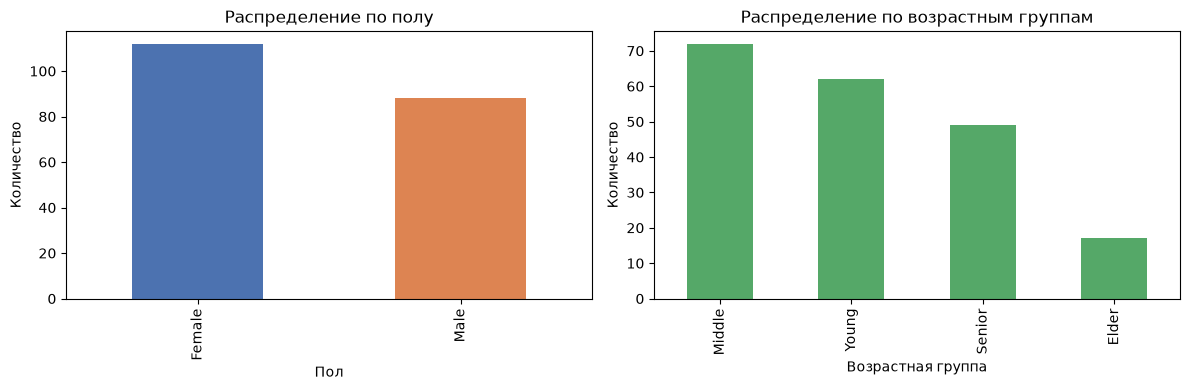

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['Gender'].value_counts().plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('Распределение по полу')
axes[0].set_xlabel('Пол')
axes[0].set_ylabel('Количество')

df['AgeGroup'].value_counts().plot(kind='bar', ax=axes[1], color='#55A868')
axes[1].set_title('Распределение по возрастным группам')
axes[1].set_xlabel('Возрастная группа')
axes[1].set_ylabel('Количество')

plt.tight_layout()
plt.show()

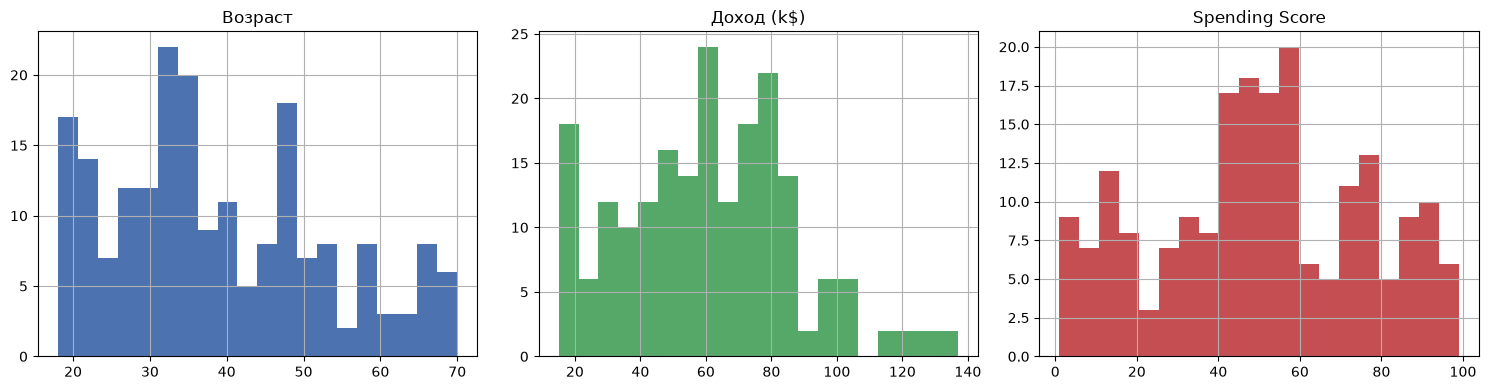

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df['Age'].hist(bins=20, ax=axes[0], color='#4C72B0')
axes[0].set_title('Возраст')

df['Income'].hist(bins=20, ax=axes[1], color='#55A868')
axes[1].set_title('Доход (k$)')

df['SpendingScore'].hist(bins=20, ax=axes[2], color='#C44E52')
axes[2].set_title('Spending Score')

plt.tight_layout()
plt.show()

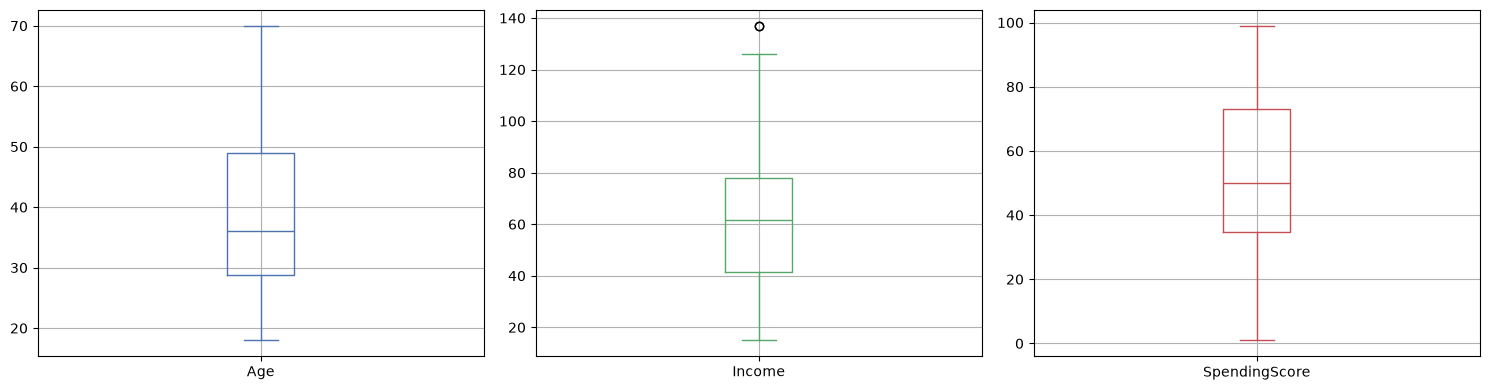

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df.boxplot(column='Age', ax=axes[0], color='#4C72B0')
df.boxplot(column='Income', ax=axes[1], color='#55A868')
df.boxplot(column='SpendingScore', ax=axes[2], color='#C44E52')

plt.tight_layout()
plt.show()

In [55]:
for col in ['Age', 'Income', 'SpendingScore']:
    print(f"{col}: min={df[col].min()}, max={df[col].max()}, "
          f"mean={df[col].mean():.2f}, median={df[col].median():.2f}")

Age: min=18, max=70, mean=38.85, median=36.00
Income: min=15, max=137, mean=60.56, median=61.50
SpendingScore: min=1, max=99, mean=50.20, median=50.00


In [57]:
df.groupby('Gender')['Income'].mean()


Gender
Female    59.250000
Male      62.227273
Name: Income, dtype: float64

In [58]:
df.groupby('Gender')['SpendingScore'].mean()


Gender
Female    51.526786
Male      48.511364
Name: SpendingScore, dtype: float64

In [59]:
df.groupby('Gender')['Age'].mean()

Gender
Female    38.098214
Male      39.806818
Name: Age, dtype: float64

In [62]:
df.groupby('AgeGroup')[['Income', 'SpendingScore', 'Age']].mean()

,Income,SpendingScore,Age
AgeGroup,,,
Young,55.209677,61.032258,23.951613
Middle,69.388889,52.569444,36.305556
Senior,58.020408,35.102041,51.795918
Elder,50.000000,44.176471,66.647059


In [61]:
df.groupby(['Gender', 'AgeGroup']).size()

Gender  AgeGroup
Female  Young       34
        Middle      44
        Senior      28
        Elder        6
Male    Young       28
        Middle      28
        Senior      21
        Elder       11
dtype: int64

In [64]:
pd.crosstab(df['Gender'], df['AgeGroup'])

AgeGroup,Young,Middle,Senior,Elder
Gender,,,,
Female,34,44,28,6
Male,28,28,21,11


In [65]:
pd.crosstab(df['IncomeGroup'], df['SpendingGroup'])

SpendingGroup,Low,Medium,High
IncomeGroup,,,
Low,23,8,19
Medium,3,71,2
High,37,4,33


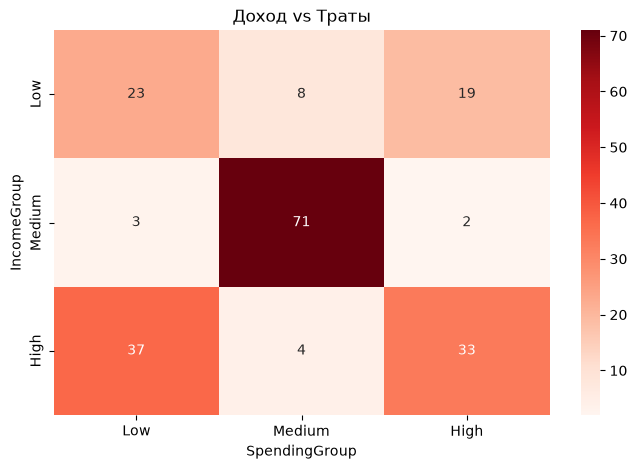

In [70]:
plt.figure(figsize=(8, 5))
sns.heatmap(pd.crosstab(df['IncomeGroup'], df['SpendingGroup']),
            annot=True, fmt='d', cmap='Reds')
plt.title('Доход vs Траты')
plt.show()

In [71]:
df[['Age', 'Income', 'SpendingScore']].corr()

,Age,Income,SpendingScore
Age,1.000000,-0.012398,-0.327227
Income,-0.012398,1.000000,0.009903
SpendingScore,-0.327227,0.009903,1.000000


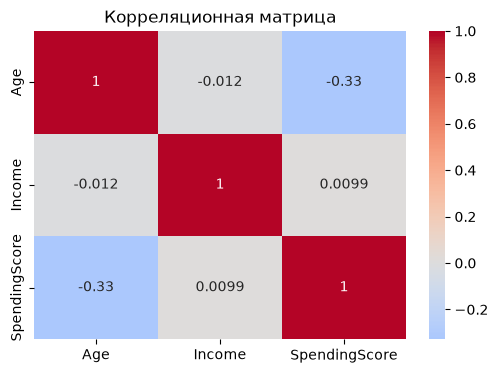

In [75]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Age', 'Income', 'SpendingScore']].corr(),
            annot=True, cmap='coolwarm', center=0)
plt.title('Корреляционная матрица')
plt.show()

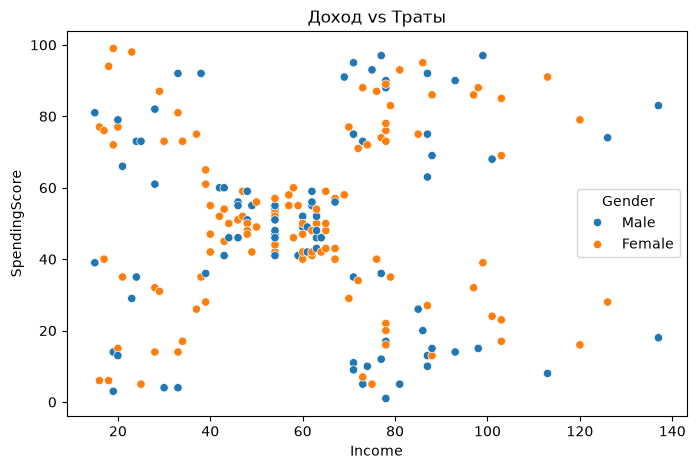

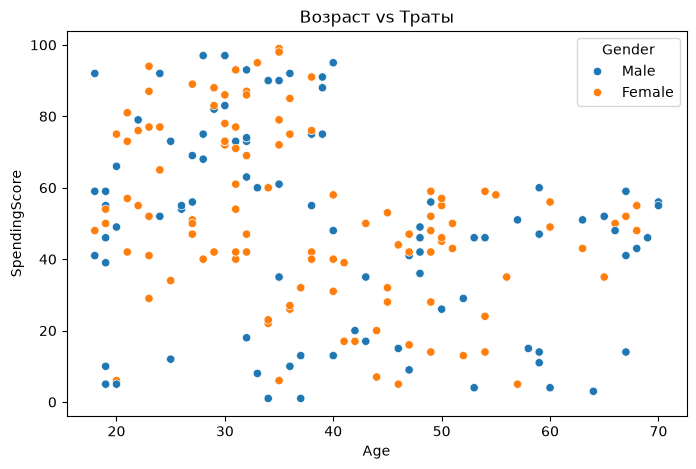

In [76]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Income', y='SpendingScore', hue='Gender')
plt.title('Доход vs Траты')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='SpendingScore', hue='Gender')
plt.title('Возраст vs Траты')
plt.show()

In [83]:
df.sort_values('Income', ascending=False).head(10)

,CustomerID,Gender,Age,Income,SpendingScore,AgeGroup,IncomeGroup,SpendingGroup
199,200,Male,30,137,83,Young,High,High
198,199,Male,32,137,18,Middle,High,Low
197,198,Male,32,126,74,Middle,High,High
196,197,Female,45,126,28,Middle,High,Low
195,196,Female,35,120,79,Middle,High,High
194,195,Female,47,120,16,Senior,High,Low
193,194,Female,38,113,91,Middle,High,High
192,193,Male,33,113,8,Middle,High,Low
190,191,Female,34,103,23,Middle,High,Low
189,190,Female,36,103,85,Middle,High,High


In [79]:
df.sort_values('SpendingScore', ascending=False).head(10)

,CustomerID,Gender,Age,Income,SpendingScore,AgeGroup,IncomeGroup,SpendingGroup
11,12,Female,35,19,99,Middle,Low,High
19,20,Female,35,23,98,Middle,Low,High
145,146,Male,28,77,97,Young,High,High
185,186,Male,30,99,97,Young,High,High
127,128,Male,40,71,95,Middle,High,High
167,168,Female,33,86,95,Middle,High,High
7,8,Female,23,18,94,Young,Low,High
141,142,Male,32,75,93,Middle,High,High
163,164,Female,31,81,93,Middle,High,High
41,42,Male,24,38,92,Young,Low,High


In [80]:
df.sort_values('Age').head(10)

,CustomerID,Gender,Age,Income,SpendingScore,AgeGroup,IncomeGroup,SpendingGroup
114,115,Female,18,65,48,Young,Medium,Medium
91,92,Male,18,59,41,Young,Medium,Medium
65,66,Male,18,48,59,Young,Medium,Medium
33,34,Male,18,33,92,Young,Low,High
0,1,Male,19,15,39,Young,Low,Low
162,163,Male,19,81,5,Young,High,Low
138,139,Male,19,74,10,Young,High,Low
115,116,Female,19,65,50,Young,Medium,Medium
113,114,Male,19,64,46,Young,Medium,Medium
111,112,Female,19,63,54,Young,Medium,Medium


In [82]:
df.sort_values('Age', ascending=False).head(10)

,CustomerID,Gender,Age,Income,SpendingScore,AgeGroup,IncomeGroup,SpendingGroup
70,71,Male,70,49,55,Elder,Medium,Medium
60,61,Male,70,46,56,Elder,Medium,Medium
57,58,Male,69,44,46,Elder,Medium,Medium
90,91,Female,68,59,55,Elder,Medium,Medium
67,68,Female,68,48,48,Elder,Medium,Medium
108,109,Male,68,63,43,Elder,Medium,Medium
82,83,Male,67,54,41,Elder,Medium,Medium
10,11,Male,67,19,14,Elder,Low,Low
102,103,Male,67,62,59,Elder,Medium,Medium
62,63,Female,67,47,52,Elder,Medium,Medium


In [84]:
vip       = df[(df['Income'] > 80) & (df['SpendingScore'] > 80)]
rich_save = df[(df['Income'] > 80) & (df['SpendingScore'] < 40)]
spender   = df[(df['Income'] < 40) & (df['SpendingScore'] > 70)]
frugal    = df[(df['Income'] < 40) & (df['SpendingScore'] < 40)]

print("VIP:",           vip.shape[0])
print("Rich & frugal:", rich_save.shape[0])
print("Spenders:",      spender.shape[0])
print("Frugal:",        frugal.shape[0])

VIP: 11
Rich & frugal: 19
Spenders: 19
Frugal: 22


In [86]:
df.query('Income > 80 and SpendingScore > 80')

,CustomerID,Gender,Age,Income,SpendingScore,AgeGroup,IncomeGroup,SpendingGroup
163,164,Female,31,81,93,Middle,High,High
167,168,Female,33,86,95,Middle,High,High
173,174,Male,36,87,92,Middle,High,High
175,176,Female,30,88,86,Young,High,High
179,180,Male,35,93,90,Middle,High,High
181,182,Female,32,97,86,Middle,High,High
183,184,Female,29,98,88,Young,High,High
185,186,Male,30,99,97,Young,High,High
189,190,Female,36,103,85,Middle,High,High
193,194,Female,38,113,91,Middle,High,High


In [87]:
df.query('Gender == "Female" and Age < 30')

,CustomerID,Gender,Age,Income,SpendingScore,AgeGroup,IncomeGroup,SpendingGroup
2,3,Female,20,16,6,Young,Low,Low
3,4,Female,23,16,77,Young,Low,High
5,6,Female,22,17,76,Young,Low,High
7,8,Female,23,18,94,Young,Low,High
13,14,Female,24,20,77,Young,Low,High
29,30,Female,23,29,87,Young,Low,High
31,32,Female,21,30,73,Young,Low,High
35,36,Female,21,33,81,Young,Low,High
39,40,Female,20,37,75,Young,Low,High
45,46,Female,24,39,65,Young,Low,Medium


In [90]:
df['IsHighSpender'] = df['SpendingScore'].apply(lambda x: 'Yes' if x > 70 else 'No')
df['IsHighSpender'].value_counts()

IsHighSpender
No     146
Yes     54
Name: count, dtype: int64

In [92]:
df['IsHighSpender'] = np.where(df['SpendingScore'] > 70, 'Yes', 'No')
df['IsHighSpender'].value_counts()


IsHighSpender
No     146
Yes     54
Name: count, dtype: int64

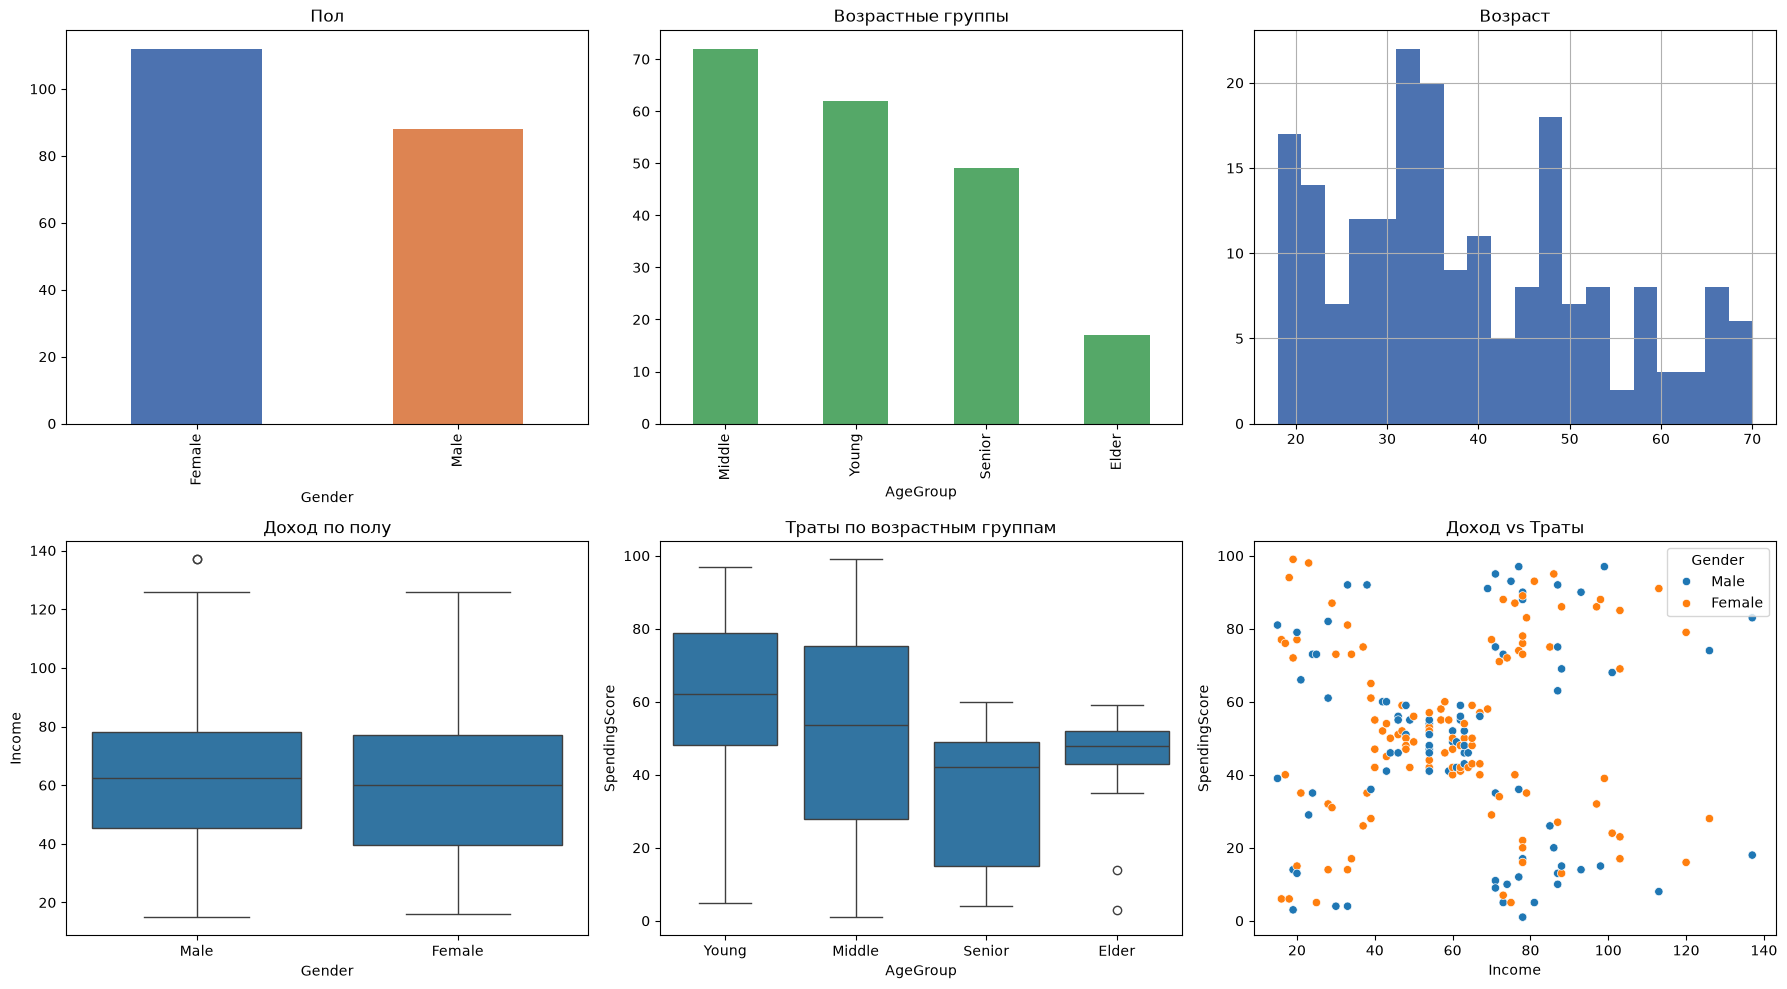

In [95]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Пол
df['Gender'].value_counts().plot(kind='bar', ax=axes[0,0], color=['#4C72B0','#DD8452'])
axes[0,0].set_title('Пол')

# Возрастные группы
df['AgeGroup'].value_counts().plot(kind='bar', ax=axes[0,1], color='#55A868')
axes[0,1].set_title('Возрастные группы')

# Гистограмма возраста
df['Age'].hist(bins=20, ax=axes[0,2], color='#4C72B0')
axes[0,2].set_title('Возраст')

# Boxplot дохода по полу
sns.boxplot(data=df, x='Gender', y='Income', ax=axes[1,0])
axes[1,0].set_title('Доход по полу')

# Boxplot трат по возрастным группам
sns.boxplot(data=df, x='AgeGroup', y='SpendingScore', ax=axes[1,1])
axes[1,1].set_title('Траты по возрастным группам')

# Scatter доход vs траты
sns.scatterplot(data=df, x='Income', y='SpendingScore', hue='Gender', ax=axes[1,2])
axes[1,2].set_title('Доход vs Траты')

plt.tight_layout()
plt.show()

In [96]:
print(f"Средний возраст: {df['Age'].mean():.1f}")
print(f"Средний доход:   {df['Income'].mean():.1f} k$")
print(f"Средний score:   {df['SpendingScore'].mean():.1f}")
print(df['Gender'].value_counts(normalize=True) * 100)

Средний возраст: 38.9
Средний доход:   60.6 k$
Средний score:   50.2
Gender
Female    56.0
Male      44.0
Name: proportion, dtype: float64


In [97]:
df.groupby('Gender')['SpendingScore'].mean()

Gender
Female    51.526786
Male      48.511364
Name: SpendingScore, dtype: float64

In [99]:
df.groupby('AgeGroup')['SpendingScore'].mean()

AgeGroup
Young     61.032258
Middle    52.569444
Senior    35.102041
Elder     44.176471
Name: SpendingScore, dtype: float64

In [100]:
df[['Income', 'SpendingScore']].corr()

,Income,SpendingScore
Income,1.000000,0.009903
SpendingScore,0.009903,1.000000


In [102]:
# VIP: много зарабатывают и много тратят
vip = df[(df['Income'] > 70) & (df['SpendingScore'] > 70)]
print(f"VIP-клиентов: {len(vip)}")
print(vip[['Age', 'Income', 'SpendingScore']].describe().round(1))

VIP-клиентов: 33
        Age  Income  SpendingScore
count  33.0    33.0           33.0
mean   32.9    86.6           83.8
std     3.7    16.8            8.3
min    27.0    71.0           71.0
25%    30.0    76.0           75.0
50%    32.0    78.0           86.0
75%    36.0    93.0           90.0
max    40.0   137.0           97.0


In [103]:
vip       = df[(df['Income'] > 70) & (df['SpendingScore'] > 70)]
rich_save = df[(df['Income'] > 70) & (df['SpendingScore'] < 40)]
spender   = df[(df['Income'] < 40) & (df['SpendingScore'] > 70)]
frugal    = df[(df['Income'] < 40) & (df['SpendingScore'] < 40)]

print(f"VIP:          {len(vip):>3} чел. ({len(vip)/len(df)*100:.1f}%)")
print(f"Rich-frugal:  {len(rich_save):>3} чел. ({len(rich_save)/len(df)*100:.1f}%)")
print(f"Spenders:     {len(spender):>3} чел. ({len(spender)/len(df)*100:.1f}%)")
print(f"Frugal:       {len(frugal):>3} чел. ({len(frugal)/len(df)*100:.1f}%)")

VIP:           33 чел. (16.5%)
Rich-frugal:   36 чел. (18.0%)
Spenders:      19 чел. (9.5%)
Frugal:        22 чел. (11.0%)


# Conclusions

## Данные
- Датасет: 200 клиентов, 5 признаков (Age, Gender, Income, SpendingScore).
- Пропусков и дублей нет.

## Ключевые инсайты
1. Средний возраст клиента — 39 лет, средний доход — 60.5.
2. **Корреляция дохода и трат = 0.01** — деньги не определяют поведение.
3. **Молодые (18–30) тратят больше всех** (средний score 61).
4. Женщины тратят чуть больше мужчин (51 vs 49).
5. Видны **5 кластеров** клиентов на графике Income vs SpendingScore.

## Сегменты клиентов
| Сегмент | Доход | Траты | Размер | Приоритет |
|---|---|---|---|---|
| VIP | Высокий | Высокие | ~20 | Высокий |
| Богатые-экономные | Высокий | Низкие | ~30 | Высокий |
| Транжиры | Низкий | Высокие | ~20 | Средний |
| Экономные | Низкий | Низкие | ~40 | Низкий |
| Средние | Средний | Средние | ~90 | Средний |

## Бизнес-рекомендации
1. Программа лояльности для VIP-сегмента.
2. Персонализированные предложения для «богатых-экономных».
3. Молодёжные акции для клиентов 18–30.
4. Таргетинг на женщин 30–45 с высоким доходом.

## Ограничения анализа
- Датасет всего 200 строк — выводы осторожные.
- Нет данных о частоте покупок и категориях товаров.